# Projet F7 : détection d'anomalies sur le S&P 500

**Question de recherche :** quelles journées de marché sont statistiquement atypiques, et correspondent-elles à des événements connus ?

**Type de problème :** apprentissage **non supervisé** (détection d'anomalies, sans étiquettes).

**Données :** indice S&P 500, série quotidienne issue de FRED (Federal Reserve Bank of St. Louis), identifiant `SP500`.

**Modèles :** Isolation Forest et LOF (Local Outlier Factor).

**Réalisé par :** Alaa Saad et Hiba Tiamani

## Plan

1. Chargement et nettoyage des données
2. Construction des variables (rendements logarithmiques, volatilité glissante)
3. Détection d'anomalies (Isolation Forest, LOF)
4. Comparaison avec des événements de marché documentés
5. Sensibilité au paramètre de proportion d'anomalies
6. Limites et conclusion

In [1]:
# Bibliothèques utilisées
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Réglages d'affichage
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

# Graine aléatoire : garantit des résultats reproductibles
SEED = 42

## 1. Chargement et nettoyage des données

Le fichier CSV est lu directement depuis FRED. Dans ce fichier, les jours sans cotation (jours fériés) sont codés par un point « . » : on les convertit en valeurs manquantes (NaN), puis on les supprime.

In [2]:
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"

# na_values=["."] : FRED code les valeurs manquantes par un point
brut = pd.read_csv(URL, na_values=["."])

print("Dimensions du fichier brut :", brut.shape)
brut.head()

Dimensions du fichier brut : (2609, 2)


,observation_date,SP500
0,2016-11-07,2131.52
1,2016-11-08,2139.56
2,2016-11-09,2163.26
3,2016-11-10,2167.48
4,2016-11-11,2164.45


In [3]:
# On renomme les colonnes (le nom de la colonne de dates a changé selon les versions de FRED)
df = brut.copy()
df.columns = ["date", "sp500"]

# Conversion des types
df["date"] = pd.to_datetime(df["date"])
df["sp500"] = pd.to_numeric(df["sp500"], errors="coerce")

# Suppression des valeurs manquantes, tri chronologique, dates en index
print("Valeurs manquantes supprimées :", df["sp500"].isna().sum())
df = df.dropna().sort_values("date").set_index("date")

print("Période couverte :", df.index.min().date(), "au", df.index.max().date())
print("Nombre d'observations :", len(df))
df.describe()

Valeurs manquantes supprimées : 96
Période couverte : 2016-11-07 au 2026-11-05
Nombre d'observations : 2513


,sp500
count,2513.000000
mean,4213.982591
std,1515.384160
min,2131.520000
25%,2867.190000
50%,3999.090000
75%,5209.910000
max,7818.930000


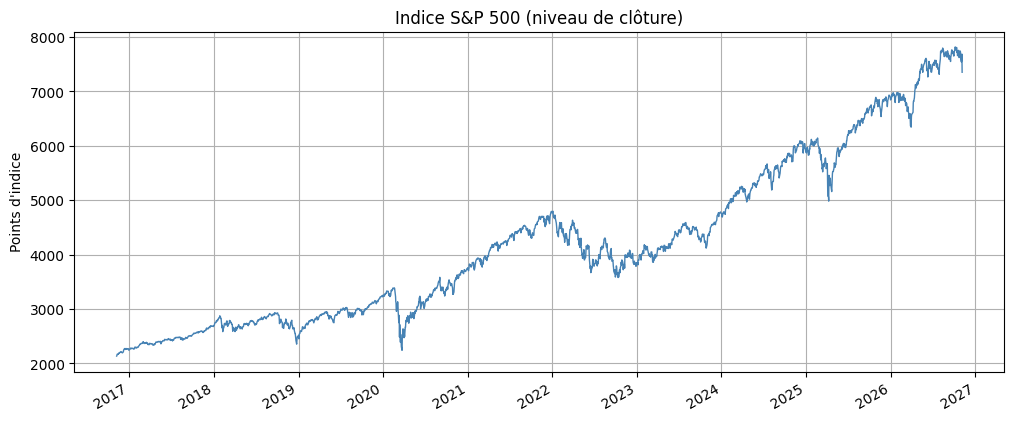

In [4]:
# Premier coup d'oeil : évolution du cours
ax = df["sp500"].plot(color="steelblue", linewidth=1)
ax.set_title("Indice S&P 500 (niveau de clôture)")
ax.set_xlabel("")
ax.set_ylabel("Points d'indice")
plt.show()

## 2. Construction des variables

On ne détecte pas les anomalies sur le **niveau** de l'indice (il monte avec le temps), mais sur deux variables plus stables :

- le **rendement logarithmique quotidien** : $r_t = \ln(P_t) - \ln(P_{t-1})$ ;
- la **volatilité glissante sur 20 jours** : écart-type des rendements des 20 derniers jours de cotation (environ un mois).

Le rendement capte les mouvements brusques d'un jour ; la volatilité capte les périodes de tension prolongée.

In [5]:
df["rendement"] = np.log(df["sp500"]).diff()
df["volatilite_20j"] = df["rendement"].rolling(window=20).std()

# Les premières lignes n'ont pas assez d'historique : on les retire
df = df.dropna().copy()

print("Observations utilisables :", len(df))
df[["rendement", "volatilite_20j"]].describe()

Observations utilisables : 2493


,rendement,volatilite_20j
count,2493.000000,2493.000000
mean,0.000483,0.009446
std,0.011493,0.006574
min,-0.127652,0.002069
25%,-0.003794,0.005710
50%,0.000800,0.007746
75%,0.005897,0.011355
max,0.090895,0.061669


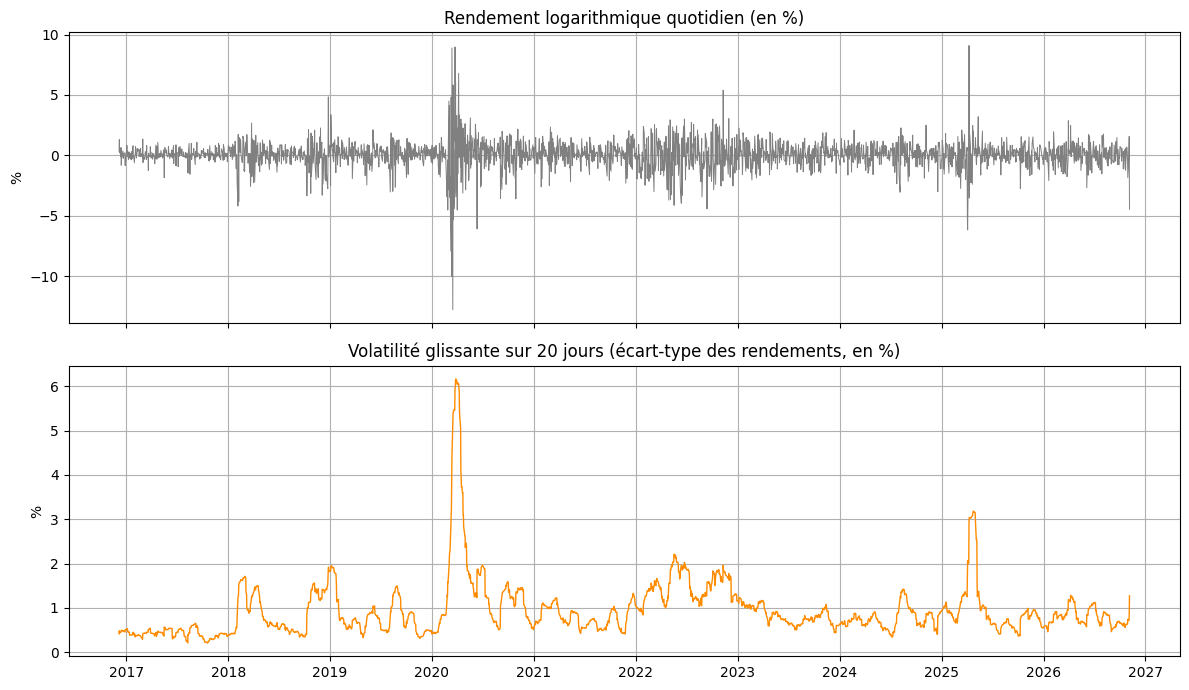

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df.index, df["rendement"] * 100, color="gray", linewidth=0.7)
axes[0].set_title("Rendement logarithmique quotidien (en %)")
axes[0].set_ylabel("%")

axes[1].plot(df.index, df["volatilite_20j"] * 100, color="darkorange", linewidth=1)
axes[1].set_title("Volatilité glissante sur 20 jours (écart-type des rendements, en %)")
axes[1].set_ylabel("%")

plt.tight_layout()
plt.show()

## 3. Détection d'anomalies

### Les deux modèles

- **Isolation Forest** : construit des arbres qui découpent les données au hasard. Un point atypique est « isolé » en peu de découpages, donc son score d'anomalie est élevé.
- **LOF (Local Outlier Factor)** : compare la densité locale autour d'un point à celle de ses voisins. Un point situé dans une zone beaucoup moins dense que ses voisins est atypique.

### Le paramètre `contamination`

Il fixe la **proportion de journées** que l'on accepte de classer comme anomalies. C'est un choix de l'analyste, pas un résultat : on prend ici **2 %** comme valeur de départ, puis on teste d'autres valeurs à l'étape 5.

### Standardisation

Les deux variables n'ont pas la même échelle. On les standardise (moyenne 0, écart-type 1) pour qu'aucune ne domine, ce qui est surtout important pour LOF, un modèle fondé sur des distances.

In [7]:
CONTAMINATION = 0.02   # proportion d'anomalies attendue (hypothèse de départ)

variables = ["rendement", "volatilite_20j"]
X = df[variables].values
X_std = StandardScaler().fit_transform(X)

# --- Isolation Forest ---
iso = IsolationForest(n_estimators=300, contamination=CONTAMINATION, random_state=SEED)
df["anomalie_iso"] = iso.fit_predict(X_std) == -1      # True si anomalie
df["score_iso"] = -iso.score_samples(X_std)            # plus élevé = plus atypique

# --- LOF ---
lof = LocalOutlierFactor(n_neighbors=35, contamination=CONTAMINATION)
df["anomalie_lof"] = lof.fit_predict(X_std) == -1
df["score_lof"] = -lof.negative_outlier_factor_        # plus élevé = plus atypique

print(f"Isolation Forest : {df['anomalie_iso'].sum()} anomalies sur {len(df)} jours")
print(f"LOF              : {df['anomalie_lof'].sum()} anomalies sur {len(df)} jours")

Isolation Forest : 50 anomalies sur 2493 jours
LOF              : 50 anomalies sur 2493 jours


In [8]:
# Les deux modèles repèrent-ils les mêmes journées ?
les_deux = (df["anomalie_iso"] & df["anomalie_lof"]).sum()
au_moins_un = (df["anomalie_iso"] | df["anomalie_lof"]).sum()

print("Journées signalées par les deux modèles :", les_deux)
print("Journées signalées par au moins un modèle :", au_moins_un)
print(f"Recouvrement (indice de Jaccard) : {les_deux / au_moins_un:.2f}")

Journées signalées par les deux modèles : 36
Journées signalées par au moins un modèle : 64
Recouvrement (indice de Jaccard) : 0.56


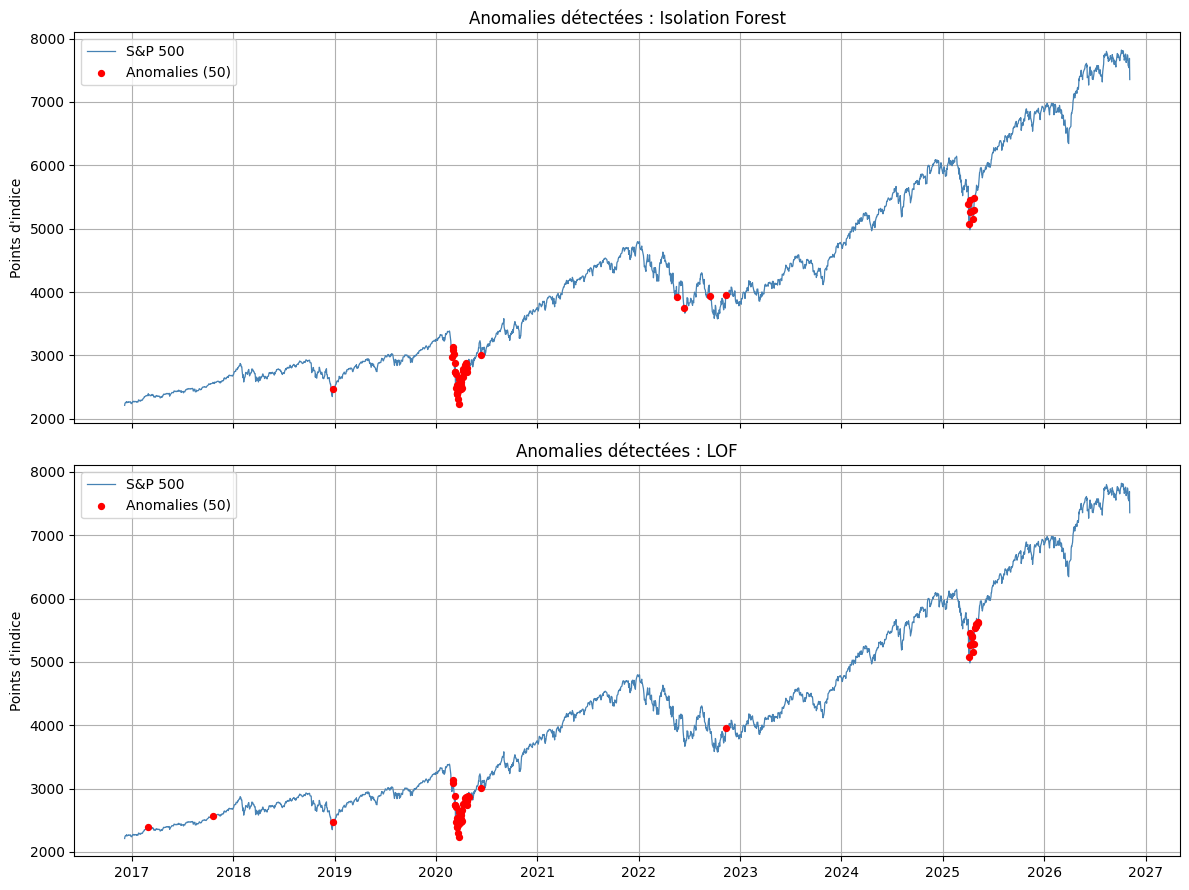

In [9]:
# Frise chronologique des anomalies détectées
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for ax, col, titre in zip(axes,
                          ["anomalie_iso", "anomalie_lof"],
                          ["Isolation Forest", "LOF"]):
    ax.plot(df.index, df["sp500"], color="steelblue", linewidth=0.9, label="S&P 500")
    pts = df[df[col]]
    ax.scatter(pts.index, pts["sp500"], color="red", s=18, zorder=3,
               label=f"Anomalies ({len(pts)})")
    ax.set_title(f"Anomalies détectées : {titre}")
    ax.set_ylabel("Points d'indice")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 4. Comparaison avec des événements de marché documentés

Sans étiquettes, on ne peut pas calculer d'exactitude. On évalue donc les résultats **qualitativement** : les anomalies tombent-elles dans des périodes de tension connues ?

D'abord, les 15 journées jugées les plus atypiques par Isolation Forest. À toi de les rapprocher d'événements (cherche la date dans un journal financier ou sur Wikipédia).

In [10]:
top = (df.sort_values("score_iso", ascending=False)
         .head(15)[["sp500", "rendement", "volatilite_20j", "score_iso"]]
         .copy())
top["rendement (%)"] = (top["rendement"] * 100).round(2)
top["volatilité 20j (%)"] = (top["volatilite_20j"] * 100).round(2)
top["score_iso"] = top["score_iso"].round(3)
top = top[["sp500", "rendement (%)", "volatilité 20j (%)", "score_iso"]].sort_index()
top

,sp500,rendement (%),volatilité 20j (%),score_iso
date,,,,
2020-03-12,2480.64,-9.99,3.75,0.790
2020-03-13,2711.02,8.88,4.41,0.792
2020-03-16,2386.13,-12.77,5.11,0.813
2020-03-17,2529.19,5.82,5.38,0.804
2020-03-18,2398.10,-5.32,5.42,0.806
2020-03-20,2304.92,-4.43,5.47,0.801
2020-03-23,2237.40,-2.97,5.47,0.774
2020-03-24,2447.33,8.97,5.96,0.828
2020-03-26,2630.07,6.05,6.13,0.822


Ensuite, un test plus objectif : on définit des **périodes d'événements** et on regarde la part des anomalies qui y tombent, en la comparant à la part de jours que ces périodes représentent. Si les anomalies étaient réparties au hasard, les deux parts seraient proches.



In [11]:
evenements = {
    "Volmageddon (début février 2018)":          ("2018-02-01", "2018-02-14"),
    "Chute de fin 2018":                         ("2018-10-01", "2018-12-31"),
    "Krach lié au Covid-19":                     ("2020-02-20", "2020-04-30"),
    "Inflation et hausse des taux (2022)":       ("2022-01-01", "2022-10-31"),
    "Faillite de SVB (mars 2023)":               ("2023-03-08", "2023-03-20"),
    "Turbulences d'août 2024":                   ("2024-08-01", "2024-08-12"),
    "Annonces tarifaires (avril 2025)":          ("2025-04-01", "2025-04-15"),
}

lignes = []
masque = pd.Series(False, index=df.index)   # True pour les jours situés dans un événement

for nom, (debut, fin) in evenements.items():
    periode = df.loc[debut:fin]
    if periode.empty:        # événement hors de la plage de données
        continue
    masque.loc[debut:fin] = True
    lignes.append({
        "Événement": nom,
        "Jours": len(periode),
        "Anomalies Isolation Forest": int(periode["anomalie_iso"].sum()),
        "Anomalies LOF": int(periode["anomalie_lof"].sum()),
    })

tableau = pd.DataFrame(lignes)
display(tableau)

part_jours = masque.mean()
part_iso = masque.values[df["anomalie_iso"].values].mean()
part_lof = masque.values[df["anomalie_lof"].values].mean()

print(f"Part des jours situés dans ces périodes      : {part_jours:.0%}")
print(f"Part des anomalies Isolation Forest dedans   : {part_iso:.0%}")
print(f"Part des anomalies LOF dedans                : {part_lof:.0%}")

,Événement,Jours,Anomalies Isolation Forest,Anomalies LOF
0,Volmageddon (début février 2018),10,0,0
1,Chute de fin 2018,63,1,1
2,Krach lié au Covid-19,50,36,30
3,Inflation et hausse des taux (2022),209,3,0
4,Faillite de SVB (mars 2023),9,0,0
5,Turbulences d'août 2024,8,0,0
6,Annonces tarifaires (avril 2025),11,4,5


Part des jours situés dans ces périodes      : 14%
Part des anomalies Isolation Forest dedans   : 88%
Part des anomalies LOF dedans                : 72%


## 5. Sensibilité au paramètre de proportion d'anomalies

Le choix de `contamination` est arbitraire. On vérifie donc si les conclusions tiennent quand on le modifie.

In [12]:
resultats = []
for c in [0.01, 0.02, 0.03, 0.05]:
    m_iso = IsolationForest(n_estimators=300, contamination=c,
                            random_state=SEED).fit_predict(X_std) == -1
    m_lof = LocalOutlierFactor(n_neighbors=35, contamination=c).fit_predict(X_std) == -1
    resultats.append({
        "contamination": f"{c:.0%}",
        "Anomalies Isolation Forest": int(m_iso.sum()),
        "dont dans un événement": f"{masque.values[m_iso].mean():.0%}",
        "Anomalies LOF": int(m_lof.sum()),
        "dont dans un événement (LOF)": f"{masque.values[m_lof].mean():.0%}",
    })

pd.DataFrame(resultats)

,contamination,Anomalies Isolation Forest,dont dans un événement,Anomalies LOF,dont dans un événement (LOF)
0,1%,25,100%,25,92%
1,2%,50,88%,50,72%
2,3%,75,76%,75,65%
3,5%,125,70%,125,51%


## 6. Limites

- **Évaluation subjective** : sans étiquettes, il n'existe pas de « bonne réponse » pour mesurer la performance. La comparaison avec des événements reste qualitative.
- **Paramètre arbitraire** : le nombre d'anomalies est fixé par `contamination`, pas découvert par le modèle.
- **Deux variables seulement** : d'autres variables (volumes, écarts de taux, VIX) pourraient changer les résultats.
- **Période limitée** : la série FRED du S&P 500 ne couvre qu'une dizaine d'années, ce qui restreint les conclusions.
- **Anomalie ne veut pas dire erreur** : une journée atypique peut refléter un vrai événement de marché, pas un problème de données.

## Conclusion

Sur dix ans de données du S&P 500, Isolation Forest et LOF identifient 50 journées atypiques chacun (2 % de l'échantillon), avec un accord partiel (indice de Jaccard de 0,56). Ces journées se concentrent dans des périodes de turbulence connues : 88 % des anomalies d'Isolation Forest et 72 % de celles de LOF tombent dans des fenêtres qui ne couvrent que 14 % des jours. Cet effet tient en grande partie au Covid-19 et aux annonces tarifaires d'avril 2025 ; les épisodes plus modérés (Volmageddon, SVB, août 2024) et les baisses graduelles (fin 2018, 2022) passent largement inaperçus. Les résultats résistent à un changement de la proportion d'anomalies, mais l'évaluation reste qualitative. Des pistes d'amélioration seraient d'ajouter des variables (volume, VIX), de tester d'autres fenêtres de volatilité et d'utiliser une liste d'événements définie de façon plus systématique.
